# LLM が自信なく間違える質問を見つける（トークンの確率、self-consistency、semantic entropy）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/16_llm_analysis/llm_uncertainty.ipynb)

NLP クックブック 16-06 ／ LLM の評価と分析

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

答えの決まったクイズで、手元の LLM の答えのうち間違っていそうなものを、正解を見ずに見分けたい。答えのトークンの確率、何回も答えさせたときの答えの一致度、意味の同じ答えをまとめたエントロピー（semantic entropy）を比べ、自信の低い質問に答えないことにすると、残りの正解率がどれだけ上がるかも確かめたい。

In [1]:
!pip install -q datasets

In [2]:
import re, time, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from tokenizers import models
from transformers import AutoModelForCausalLM, AutoTokenizer

torch.manual_seed(0)
# AI王（クイズ AI 日本一決定戦）のクイズ 1000 問（第 2 版の検証データ）に、SB Intuitions が人手で別解を加えたもの。CC BY-SA 4.0
aio = load_dataset("sbintuitions/aio-extended-answers", split="validation")
shots = aio.select(range(5))                      # 先頭の 5 問は few-shot の例にする
N = 300                                           # 時間の都合で、続く 300 問を評価に使う
quiz = aio.select(range(5, 5 + N))
print(quiz[0]["question"], quiz[0]["answers"])

name = "sbintuitions/sarashina2.2-3b-instruct-v0.1"       # MIT ライセンス
tokenizer = AutoTokenizer.from_pretrained(name, padding_side="left")
# transformers 5 系は、このモデルの SentencePiece (Unigram) を BPE に変換してしまい、学習時と違う分割になる。
# 元の tokenizer.model から語彙とスコアを読み、分割の方式だけを Unigram に戻す（特殊トークンやチャットテンプレートはそのまま）
sp = spm.SentencePieceProcessor(model_file=hf_hub_download(name, "tokenizer.model"))
tokenizer.backend_tokenizer.model = models.Unigram(
    [(sp.id_to_piece(i), sp.get_score(i)) for i in range(sp.get_piece_size())], unk_id=sp.unk_id(), byte_fallback=True)
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="auto").eval()

INSTRUCTION = "次のクイズに答えてください。答えとなる語句だけを書き、文や説明は書かないでください。"
def prompt(question):
    msgs = []
    for ex in shots:        # 例は「ユーザーの問題 → アシスタントの答え」の対話として前に置く
        msgs += [{"role": "user", "content": f"{INSTRUCTION}\n\n問題: {ex['question']}"}, {"role": "assistant", "content": ex["answers"][0]}]
    msgs.append({"role": "user", "content": f"{INSTRUCTION}\n\n問題: {question}"})
    return tokenizer.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)

def clean(text):
    """答えの部分だけを取り出す: 1 行目だけにし、括弧の補足とかぎ括弧、「です」を除く"""
    text = text.strip().split("\n")[0]
    text = re.sub(r"[（(][^）)]*[）)]?", "", text)
    return re.sub(r"(です|だ)?[。.]?$", "", text.strip("「」『』 ")).strip("「」『』 ")

def normalize(text):
    """表記の揺れを吸収して比べるための形: NFKC、小文字、空白・記号と長音記号を除く（「コンピューター」と「コンピュータ」を同じにする）。
    長音記号を全部消すので、「ビール」と「ビル」のような別の語も同じになる（下の出力の「エンパイアステトビル」も同じ理由）"""
    return re.sub(r"[\s・･。、,.!?！？「」『』\-ー〜~]", "", unicodedata.normalize("NFKC", text).lower())

print(clean("アイザック・ニュートン\n\n（説明：万有引力の…"), clean("「君たちはどう生きるか」です。"), normalize("エンパイア・ステート・ビル"))

アメリカ・メジャーリーグの2つのリーグといえば、ナショナルリーグと何リーグ? ['アメリカン', 'アメリカンリーグ']
アイザック・ニュートン 君たちはどう生きるか エンパイアステトビル


In [3]:
# 答えは 1 行目だけを使うので、改行が出たら生成を止める。このモデルの改行はバイトのトークン <0x0A> の 1 つだけなので、終了の記号として渡す
# （stop_strings=["\n"] でも止められるが、generate を呼ぶたびに準備の時間がかかる）
STOP = [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<0x0A>")]

@torch.no_grad()
def generate(texts, n_samples=1, bs=30, **kwargs):
    """各プロンプトに n_samples 個の答えを生成し、答えの文字列と、生成したトークンの平均対数尤度を返す"""
    answers, mean_logp = [], []
    step = max(1, bs // n_samples)
    for i in range(0, len(texts), step):
        enc = tokenizer(texts[i:i + step], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, max_new_tokens=16, num_return_sequences=n_samples, eos_token_id=STOP,
                             repetition_penalty=1.0, pad_token_id=tokenizer.pad_token_id, output_logits=True, return_dict_in_generate=True, **kwargs)
        gen = out.sequences[:, enc["input_ids"].shape[1]:]
        # output_logits は温度や top-p を掛ける前の、モデルそのものの予測。各ステップで実際に選ばれたトークンの対数確率を取る
        logp = torch.stack([l.float().log_softmax(-1).gather(1, gen[:, t:t + 1])[:, 0] for t, l in enumerate(out.logits)], 1)
        mask = (gen != tokenizer.pad_token_id).float()          # 答えの終わり（</s> か改行）より後はパディング
        mean_logp += ((logp * mask).sum(1) / mask.sum(1)).tolist()
        answers += [clean(t) for t in tokenizer.batch_decode(gen, skip_special_tokens=True)]
    return np.array(answers, dtype=object).reshape(len(texts), n_samples), np.array(mean_logp).reshape(len(texts), n_samples)

texts = [prompt(ex["question"]) for ex in quiz]
golds = [{normalize(a) for a in ex["answers"]} for ex in quiz]

# (1) 貪欲法で 1 回答えさせる。この答えの正誤を、正解を見ずに予測するのが目標（Colab の T4 で 1〜2 分程度）
t = time.time()
greedy, greedy_logp = generate(texts, do_sample=False)
greedy, greedy_logp = greedy[:, 0], greedy_logp[:, 0]
correct = np.array([normalize(a) in g for a, g in zip(greedy, golds)])        # 正規化した答えが正解（別解を含む）のどれかと一致
# 参考: 文で答えた場合も拾う甘い採点（正解を含めば正解。数値の正解は前後に数字が続かないこと、それ以外は 2 文字以上）。複数の候補を並べた答えも正解になる
def contains(a, g):
    return any(re.search(rf"(?<!\d){x}(?!\d)", normalize(a)) if x.isdigit() else len(x) >= 2 and x in normalize(a) for x in g)
loose = correct | np.array([contains(a, g) for a, g in zip(greedy, golds)])
print(f"貪欲法: {time.time() - t:.0f} 秒, 正解率 {correct.mean():.3f} ({correct.sum()}/{N}), 正解を含めば正解とすると {loose.mean():.3f}")

# (2) 温度 1.0 でサンプリングして 10 回ずつ答えさせる（Colab の T4 で 6〜8 分程度）
K = 10
t = time.time()
torch.manual_seed(0)
samples, _ = generate(texts, n_samples=K, do_sample=True, temperature=1.0, top_p=0.9, top_k=50)
print(f"サンプリング {K} 回: {time.time() - t:.0f} 秒, GPU メモリ最大 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
for i in range(3):
    print(quiz[i]["answers"], "| 貪欲法:", greedy[i], f"({greedy_logp[i]:.2f})", "| サンプル:", dict(Counter(samples[i])))

貪欲法: 17 秒, 正解率 0.640 (192/300), 正解を含めば正解とすると 0.683
サンプリング 10 回: 161 秒, GPU メモリ最大 11.3 GB
['アメリカン', 'アメリカンリーグ'] | 貪欲法: アメリカンリーグ (-0.00) | サンプル: {'アメリカンリーグ': 10}
['華道'] | 貪欲法: 華道 (-0.21) | サンプル: {'華道': 7, 'いけばな': 3}
['サラウンド', 'surround', 'サラウンドサウンド'] | 貪欲法: ambisonics (-0.15) | サンプル: {'サラウンド': 3, 'ambisonics': 3, 'surround sound': 4}


In [4]:
from transformers import AutoModelForSequenceClassification, PreTrainedTokenizerFast

# 意味の同じ答えをまとめる 2 つの方法: (a) 正規化した文字列の完全一致、(b) NLI で双方向に含意するか
nli_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"     # 多言語の NLI モデル（MIT ライセンス）
# transformers 5 系の DebertaV2Tokenizer は全角の記号や英数字を [UNK] にしてしまう (issue #49622) ので、tokenizer.json から直接読む
nli_tok = PreTrainedTokenizerFast.from_pretrained(nli_name)
nli = AutoModelForSequenceClassification.from_pretrained(nli_name, device_map="auto").eval()
ENTAIL = nli.config.label2id["entailment"]

# 問題ごとに、サンプルと貪欲法の答えのうち表記の違うものの全ての順序対について、「質問 + 答え A」が「質問 + 答え B」を含意するかを調べる
pairs = []
for i, ex in enumerate(quiz):
    forms = {}
    for a in [greedy[i], *samples[i]]:
        forms.setdefault(normalize(a), a)
    pairs += [(i, a, b) for a in forms.values() for b in forms.values() if normalize(a) != normalize(b)]
entails = {}
t = time.time()
with torch.no_grad():
    for j in range(0, len(pairs), 128):
        batch = pairs[j:j + 128]
        enc = nli_tok([f"質問: {quiz[i]['question']} 答え: {a}" for i, a, b in batch],
                      [f"質問: {quiz[i]['question']} 答え: {b}" for i, a, b in batch], return_tensors="pt", padding=True, truncation=True).to(nli.device)
        pred = nli(**enc).logits.argmax(-1).tolist()
        entails.update({(i, normalize(a), normalize(b)): p == ENTAIL for (i, a, b), p in zip(batch, pred)})
print(f"NLI: {len(pairs)} 組, {time.time() - t:.0f} 秒")
# NLI が「同じ意味」（双方向に含意）と判定した、表記の違う答えの組の例
same = [(quiz[i]["answers"][0], a, b) for i, a, b in pairs if a < b and entails[i, normalize(a), normalize(b)] and entails[i, normalize(b), normalize(a)]]
print(len(same), "組:", same[:12])

def cluster(i, answers, use_nli):
    """答えのリストに意味のクラスタの番号を振る。NLI では、各クラスタの最初の答えと双方向に含意すれば同じクラスタとする"""
    reps, ids = [], []
    for a in answers:
        a = normalize(a)
        for c, r in enumerate(reps):
            if a == r or (use_nli and entails[i, a, r] and entails[i, r, a]):
                ids.append(c); break
        else:
            reps.append(a); ids.append(len(reps) - 1)
    return ids

def entropy(ids):
    p = np.array(list(Counter(ids).values())) / len(ids)
    return float(-(p * np.log(p)).sum())

scores = {}   # 値が大きいほど「自信がある」向きにそろえる
scores["平均対数尤度"] = greedy_logp
scores["一致度（完全一致）"] = np.array([np.mean([normalize(s) == normalize(g) for s in row]) for g, row in zip(greedy, samples)])
scores["一致度 (NLI)"] = np.array([np.mean([c == 0 for c in cluster(i, [g, *row], True)[1:]]) for i, (g, row) in enumerate(zip(greedy, samples))])
scores["−semantic entropy（完全一致）"] = -np.array([entropy(cluster(i, row, False)) for i, row in enumerate(samples)])
scores["−semantic entropy (NLI)"] = -np.array([entropy(cluster(i, row, True)) for i, row in enumerate(samples)])
n_clusters = {m: np.array([len(set(cluster(i, row, m))) for i, row in enumerate(samples)]) for m in [False, True]}
print(f"10 個のサンプルの意味のクラスタの数（平均）: 完全一致 {n_clusters[False].mean():.2f} / NLI {n_clusters[True].mean():.2f}")

NLI: 5084 組, 5 秒
334 組: [('サラウンド', 'surround sound', 'サラウンド'), ('しょうゆ', '酢または醤油', '酢や醤油'), ('しょうゆ', '酢または醤油', '酢や梅肉'), ('しょうゆ', '梅肉または酢', '酢や梅肉'), ('4人', '2人', '二人'), ('4人', '2', '2人'), ('4人', '2', '二人'), ('げっ歯類', 'Rodentia', 'rodent類'), ('開口一番', 'マクラ', '見切り啖呵'), ('開口一番', 'マクラ', '枕'), ('開口一番', '開け撥ね', '開口一番'), ('開口一番', '開けっ放し', '開口一番')]
10 個のサンプルの意味のクラスタの数（平均）: 完全一致 3.42 / NLI 2.77


In [5]:
from sklearn.metrics import roc_auc_score

# 誤答を見分ける AUROC: 「自信のなさ」（= −スコア）で誤答（正例）を上位に並べられるか。0.5 なら偶然、1 なら完全
rng = np.random.default_rng(0)
boot = rng.integers(0, N, (2000, N))
wrong = ~correct

def auroc_ci(s, wrong=wrong):
    vals = [roc_auc_score(wrong[b], -s[b]) for b in boot]
    return roc_auc_score(wrong, -s), *np.percentile(vals, [2.5, 97.5])

def coverage_curve(s):
    """自信の高い順に並べ、上位の割合（カバレッジ）だけに答えるとしたときの正解率。一致度などは同点が多いので、同点は平均対数尤度の高い順にする"""
    order = np.lexsort((-greedy_logp, -s))
    return np.cumsum(correct[order]) / np.arange(1, N + 1)

rows = {}
for c, s in scores.items():
    a, lo, hi = auroc_ci(s)
    curve = coverage_curve(s)
    rows[c] = {"AUROC": f"{a:.3f} [{lo:.3f}, {hi:.3f}]", "AUROC（甘い採点）": "{:.3f} [{:.3f}, {:.3f}]".format(*auroc_ci(s, ~loose)), "AURAC": round(curve.mean(), 3),
               **{f"正解率 @{p}%": round(curve[int(N * p / 100) - 1], 3) for p in [100, 80, 60, 40, 20]}}
pd.set_option("display.width", 200)
print(pd.DataFrame(rows).T.to_string())
print(f"（誤答 {wrong.sum()} 問 / {N} 問。AURAC はカバレッジ 1/N〜100% の正解率の平均。甘い採点は、正解を含めば正解とした場合）")

# 差は偶然の範囲か: 全問での AUROC の差と、同じブートストラップの標本で求めた差の 95% 信頼区間
def diff_ci(a, b):
    point = roc_auc_score(wrong, -scores[a]) - roc_auc_score(wrong, -scores[b])
    d = np.array([roc_auc_score(wrong[i], -scores[a][i]) - roc_auc_score(wrong[i], -scores[b][i]) for i in boot])
    print(f"{a} − {b}: {point:+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")

for c in ["一致度（完全一致）", "−semantic entropy（完全一致）", "−semantic entropy (NLI)"]:
    diff_ci(c, "平均対数尤度")
diff_ci("−semantic entropy (NLI)", "−semantic entropy（完全一致）")

                                        AUROC           AUROC（甘い採点）  AURAC 正解率 @100% 正解率 @80% 正解率 @60% 正解率 @40% 正解率 @20%
平均対数尤度                   0.818 [0.766, 0.865]  0.844 [0.793, 0.889]  0.841      0.64    0.746    0.822    0.883     0.95
一致度（完全一致）                0.850 [0.804, 0.891]  0.858 [0.815, 0.902]  0.859      0.64    0.754    0.839    0.925     0.95
一致度 (NLI)                0.823 [0.774, 0.872]  0.829 [0.778, 0.880]  0.853      0.64     0.75     0.85      0.9     0.95
−semantic entropy（完全一致）  0.842 [0.795, 0.886]  0.852 [0.805, 0.897]  0.856      0.64    0.746    0.861    0.925     0.95
−semantic entropy (NLI)  0.817 [0.766, 0.865]  0.825 [0.772, 0.876]  0.851      0.64    0.738    0.839      0.9     0.95
（誤答 108 問 / 300 問。AURAC はカバレッジ 1/N〜100% の正解率の平均。甘い採点は、正解を含めば正解とした場合）
一致度（完全一致） − 平均対数尤度: +0.032 [+0.001, +0.065]
−semantic entropy（完全一致） − 平均対数尤度: +0.024 [-0.007, +0.057]
−semantic entropy (NLI) − 平均対数尤度: -0.001 [-0.039, +0.035]
−semantic entropy (NLI) − −semantic entropy（完

トークンの確率（平均対数尤度の exp）: 平均確信度 0.813（正解率 0.640）, ECE 0.173
一致度 (NLI): 平均確信度 0.732（正解率 0.640）, ECE 0.115


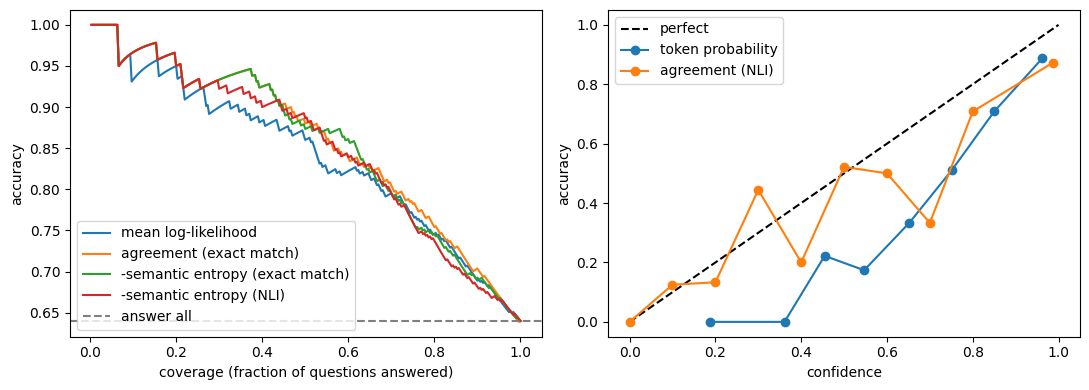

In [6]:
import matplotlib.pyplot as plt

# カバレッジと正解率のトレードオフ（左）と、確率として読めるスコアの較正（右）
labels = {"平均対数尤度": "mean log-likelihood", "一致度（完全一致）": "agreement (exact match)",
          "−semantic entropy（完全一致）": "-semantic entropy (exact match)", "−semantic entropy (NLI)": "-semantic entropy (NLI)"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cov = np.arange(1, N + 1) / N
for c, l in labels.items():
    ax[0].plot(cov, coverage_curve(scores[c]), label=l)
ax[0].axhline(correct.mean(), color="gray", ls="--", label="answer all")
ax[0].set_xlabel("coverage (fraction of questions answered)"); ax[0].set_ylabel("accuracy"); ax[0].legend()

def ece(conf, ok, n_bins=10):
    """2 値の ECE: 確信度で 10 区間に分け、|正解率 − 平均確信度| を件数で重み付けして平均する（評価指標と統計的検定の章の較正のレシピと同じ考え方）"""
    idx = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return sum((idx == b).mean() * abs(ok[idx == b].mean() - conf[idx == b].mean()) for b in range(n_bins) if (idx == b).any())

probs = {"トークンの確率（平均対数尤度の exp）": np.exp(greedy_logp), "一致度 (NLI)": scores["一致度 (NLI)"]}
ax[1].plot([0, 1], [0, 1], "k--", label="perfect")
for (c, p), l in zip(probs.items(), ["token probability", "agreement (NLI)"]):
    idx = np.minimum((p * 10).astype(int), 9)
    ax[1].plot([p[idx == b].mean() for b in range(10) if (idx == b).any()], [correct[idx == b].mean() for b in range(10) if (idx == b).any()], "o-", label=l)
    print(f"{c}: 平均確信度 {p.mean():.3f}（正解率 {correct.mean():.3f}）, ECE {ece(p, correct):.3f}")
ax[1].set_xlabel("confidence"); ax[1].set_ylabel("accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# 自信のない誤答と、自信のある誤答を見る（一致度 (NLI) の低い順・高い順）
df = pd.DataFrame({"問題": [ex["question"][:40] for ex in quiz], "正解": [ex["answers"][0] for ex in quiz], "貪欲法": [a[:20] for a in greedy],
                   "正解を含む": loose, "一致度": scores["一致度 (NLI)"], "平均対数尤度": greedy_logp.round(2),
                   "サンプル（多い順に 3 つ）": [", ".join(f"{a[:15]}×{n}" for a, n in Counter(r).most_common(3)) for r in samples]})
print("--- 自信のない誤答"); print(df[wrong].sort_values("一致度", kind="stable").head(5).to_string())
print("--- 自信のある誤答"); print(df[wrong].sort_values(["一致度", "平均対数尤度"], ascending=False, kind="stable").head(8).to_string())
print("--- 一致度ごとの問題数と正解率"); print(df.assign(正解か=correct).groupby(pd.cut(df["一致度"], [-0.01, 0.2, 0.5, 0.8, 0.99, 1.0]), observed=True)["正解か"].agg(["count", "mean"]).round(3).to_string())

--- 自信のない誤答
                                           問題    正解                   貪欲法  正解を含む  一致度  平均対数尤度                                           サンプル（多い順に 3 つ）
41       組織の内部にいながらその組織に害を及ぼす者のことを俗に「何の虫」という?  獅子身中                  組織の癌  False  0.0   -0.62                      獅子身中の虫×2, 組織内部のスパイや裏切り者を意×1, 組織の虫×1
50   戦国武将の加藤清正が朝鮮から日本に持ち込んだことから「キヨマサニンジン」とも呼ば   セロリ                  高麗人参  False  0.0   -0.47                                   朝鮮ニンジン×5, 朝鮮人参×4, セリ×1
67   野球は3アウトでチェンジですが、野球の原型となったクリケットは何アウトでチェンジ    10     クリケットは1イニングで15アウト  False  0.0   -0.74  クリケットは1セットで5アウト×1, クリケットは1試合あたり5回ず×1, クリケットは5アウトでチェンジ×1
103  うどんの上に生卵を乗せる「月見うどん」で、黄身は月に見立てていますが、白身は何に     雲  月見うどんの白身は、月に見立てた黄身を覆  False  0.0   -0.36  月見うどんの白身は、特に何かを×1, 月見うどんの白身は、 moon×1, 月見うどんの白身は、月は丸い形×1
226  タナカ、カトウ、ケンモツ、ヤマワキ、グシケン、モリスエといえば、体操のどの種目の   平行棒   シライ/キムヒフン、カトウ、ケンモツ、  False  0.0   -0.40  体操の個人総合や種目別の床運動×1, シッティングアセンブリー、後方×1, アテネ五輪で金メダルを獲得した×1
--- 自信のある誤答
                                           問題         正解            貪欲

- 3 つの確信度: 平均対数尤度は、貪欲法の答えの各トークンの対数確率を平均したもの（長さで割らないと長い答えほど低くなる）。一致度は、温度 1.0 で 10 回答えさせて貪欲法の答えと同じ答えが出た割合で、self-consistency (Wang et al., 2023) の考え方（答えがどれだけそろうか）を確信度に使う（大規模言語モデルの章の「考える過程を書かせて LLM に算数の文章題を解かせる（Chain-of-Thought と self-consistency）」の注意書きでも、票の集まり方が確信度の目安になった）。semantic entropy は Kuhn et al. (ICLR 2023) が提案し、Farquhar et al. (Nature, 2024) が幻覚（作話）の検出に使った方法で、意味の同じ答えを 1 つのクラスタにまとめてから、クラスタの分布のエントロピーを測る。ここでは Farquhar et al. にならって、10 回のサンプリングを温度 1、top-p 0.9、top-k 50 で行い、各クラスタの確率をサンプルの数の割合で近似する「離散の semantic entropy」を使った（論文では、正誤を判定する答えは温度 0.1 で生成している。ここでは貪欲法）。
- 誤答を見分ける AUROC は、平均対数尤度 0.818 [0.766, 0.865]、一致度（完全一致）0.850 [0.804, 0.891]、semantic entropy（完全一致）0.842 [0.795, 0.886] だった（正解率 64.0%、誤答 108 問 / 300 問）。同じ問題で比べた差は、一致度 − 平均対数尤度が +0.032 [+0.001, +0.065] で、0 をかろうじて外れる程度、semantic entropy − 平均対数尤度は +0.024 [−0.007, +0.057] で偶然の範囲だった。サンプリングは生成の量が 10 倍になる（検証の GPU で貪欲法 17 秒、サンプリング約 160 秒）ので、1 回の生成で得られるトークンの確率も十分に使える手がかりである。`generate` で `repetition_penalty=1.0` を明示しているのは、このモデルの generation_config の既定値 1.05 を使わないためである。
- 意味の同じ答えを NLI でまとめると、10 個のサンプルのクラスタの数は平均 3.42 から 2.77 に減った。「サラウンド」と「surround sound」、「2人」と「二人」のような言い換えはまとまる一方で、「開けっ放し」と「開口一番」、「酢または醤油」と「酢や梅肉」のような別の答えもまとめてしまい、semantic entropy の AUROC は完全一致でまとめた場合より 0.026 [0.003, 0.050] 低かった（0.817）。使った NLI のモデルは MNLI と XNLI（日本語を含まない）で学習したもので、この結果からは、日本語の短い答えの同値判定は苦手と考えられる。semantic entropy の効き目は、意味が同じかどうかの判定の質で決まる。Farquhar et al. も主な実験では GPT-3.5 に判定させている。日本語の NLI データ（JNLI など）で学習したモデルや、より大きな LLM に判定させる方法（この章の「手元の LLM に生成文を採点させる (LLM-as-a-judge)」）を試すとよい。
- 自信の低い質問に答えないことにすると、残りの正解率は上がる。全問に答えると 64.0% のところ、一致度（完全一致）の高い 60% に答えると 83.9%、40% では 92.5% になった（平均対数尤度では 82.2%、88.3%）。AURAC（Farquhar et al. の指標で、カバレッジを変えたときの正解率の平均）はどのスコアも 0.84〜0.86 で、差は小さい。一致度は 11 段階しかなく同点が多いので、カバレッジの曲線では同点を平均対数尤度で並べている。実際に使うときは、答えないしきい値を評価とは別の検証データで決める。
- 較正との違い: AUROC は誤答を上位に並べられるか（順位）だけを見て、確信度の値が正解率と合っているかは見ない。それを見るのが ECE である（評価指標と統計的検定の章の「モデルの確信度が当てになるか調べる（較正、ECE）」）。トークンの確率（平均対数尤度の exp）は平均 0.813 で、正解率 0.640 より高い自信過剰で ECE は 0.173、一致度 (NLI) は平均 0.732 で ECE 0.115 だった。右の図では、どちらも確信度 0.8 以上の区間で対角線より下にある。確率として表示したりしきい値を「確率 90%」のように決めたりするなら、検証データで較正（temperature scaling や isotonic 回帰）してから使う。300 問を 10 区間に分けているので、区間ごとの正解率はばらつきが大きい。
- 確信度で見分けられるのは「自信のない誤答」だけである。一致度 (NLI) が 1（10 回とも貪欲法の答えと同じ意味と判定）の 134 問でも 10.4% は誤りで、「侘び茶の創始者」に「千利休」（正解は村田珠光）、「1 リットルは何デシリットル」に「100」と、毎回同じ誤りを答える。Farquhar et al. も、対象は答えが毎回ばらつく作話 (confabulation) で、誤ったデータで学習したことなどによる一貫した誤りには役立たないとしている。一方、自信のない誤答のサンプルには、正解（「獅子身中の虫」）が混ざっていることもある。
- 採点の誤りにも注意する。正規化した文字列と正解（別解を含む）の完全一致で採点しているので、「パラジウムの原子番号は46」のように文で答えたものや、「ボッティチェッリ」（正解の表記はボッティチェリ）は誤答になる。逆に `normalize` は長音記号を除くので、「ビール」と「ビル」のような別の語を正解にしてしまうこともある。正解を含めば正解とする甘い採点では正解率は 68.3% になり、AUROC は完全一致でまとめた一致度 (0.858) と semantic entropy (0.852) が上位なのは同じだった。「自信のある誤答」の表は、まず採点の誤りを探すのにも使える。
- データとモデル: sbintuitions/aio-extended-answers は、AI王（クイズ AI 日本一決定戦）のデータセット第 2 版の検証データ 1000 問に、SB Intuitions が人手で別解を加えたもので、データセットカードによると CC BY-SA 4.0 である。モデルは sbintuitions/sarashina2.2-3b-instruct-v0.1（MIT ライセンス）と MoritzLaurer/mDeBERTa-v3-base-mnli-xnli（MIT ライセンス）。クイズは公開されているので、事前学習のデータに含まれていれば正解率は実力より高く出る（この章の「ベンチマークの評価データが学習に漏れていないかを調べる（データ汚染の検出）」）。LLM の生成での GPU メモリの最大は 11.3 GB で、T4 (15GB) に収まる。トークナイザーの修正については、大規模言語モデルの章の「オープンな LLM とチャットする（チャットテンプレート）」の注意書きを参照。